<a href="https://colab.research.google.com/github/sajalsingh1992-arch/bank-customer-churn-prediction/blob/main/cats_v_dogs_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q --upgrade kaggle


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [ ]:
!kaggle --version

Kaggle CLI 2.2.5


In [ ]:
!kaggle competitions list


ref                                                                           deadline             category         reward  teamCount  userHasEntered  userRank  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  --------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False         0  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False         0  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False         0  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False         0  
https://www.kaggle.com/compe

In [ ]:
import os

os.makedirs("/content/cats_dogs_data", exist_ok=True)

!kaggle competitions download \
    -c dogs-vs-cats \
    -p /content/cats_dogs_data

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFiles

You don't have access to this resource.
If this is a competition, you may need to accept its rules first at
  https://www.kaggle.com/competitions/<competition>/rules


In [ ]:
!kaggle datasets download \
    -d salader/dogsvscats \
    -p /content/cats_dogs_data

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [01:03<00:00, 18.0MB/s]



In [ ]:
import os

print(os.listdir("/content/cats_dogs_data"))

['dogsvscats.zip']


In [ ]:
!mkdir -p /content/cats_dogs_data

!kaggle datasets download \
    -d salader/dogsvscats \
    -p /content/cats_dogs_data

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
dogsvscats.zip: Skipping, found more recently modified local copy (use --force to force download)


In [10]:
import os

folder = "/content/cats_dogs_data"

print(os.listdir(folder))

['dogsvscats.zip']


In [11]:
import zipfile

zip_path = "/content/cats_dogs_data/dogsvscats.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/cats_dogs_data")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [12]:
import os

for root, dirs, files in os.walk("/content/cats_dogs_data"):
    print(root, "Images/files:", len(files))

/content/cats_dogs_data Images/files: 1
/content/cats_dogs_data/train Images/files: 0
/content/cats_dogs_data/train/cats Images/files: 10000
/content/cats_dogs_data/train/dogs Images/files: 10000
/content/cats_dogs_data/test Images/files: 0
/content/cats_dogs_data/test/cats Images/files: 2500
/content/cats_dogs_data/test/dogs Images/files: 2500
/content/cats_dogs_data/catsvsdogs Images/files: 0
/content/cats_dogs_data/catsvsdogs/train Images/files: 0
/content/cats_dogs_data/catsvsdogs/train/cats Images/files: 10000
/content/cats_dogs_data/catsvsdogs/train/dogs Images/files: 10000
/content/cats_dogs_data/catsvsdogs/test Images/files: 0
/content/cats_dogs_data/catsvsdogs/test/cats Images/files: 2500
/content/cats_dogs_data/catsvsdogs/test/dogs Images/files: 2500


In [13]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D ,Flatten

In [19]:
import tensorflow as tf
from tensorflow import keras

train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/cats_dogs_data/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256),
    validation_split=0.2,
    subset='training',
    seed=42
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/cats_dogs_data/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256),
    validation_split=0.2,
    subset='validation',
    seed=42
)

test_ds = keras.utils.image_dataset_from_directory(
    directory='/content/cats_dogs_data/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256),
    shuffle=False
)


Found 20000 files belonging to 2 classes.
Using 16000 files for training.
Found 20000 files belonging to 2 classes.
Using 4000 files for validation.
Found 5000 files belonging to 2 classes.


In [20]:
print("Training batches:", len(train_ds))
print("Validation batches:", len(validation_ds))
print("Testing batches:", len(test_ds))

print("Class names:", train_ds.class_names)

Training batches: 500
Validation batches: 125
Testing batches: 157
Class names: ['cats', 'dogs']


In [21]:
# normalize
def process(image, label):
  image= tf.cast(image/256.0,tf.float32)
  return image, label
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)
test_ds = test_ds.map(process)

In [22]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 256, 256, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.99609375


In [32]:
# data augmentation
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])


In [33]:


from tensorflow import keras
from tensorflow.keras import layers, regularizers

model = keras.Sequential([

    layers.Input(shape=(256, 256, 3)),

    # Data Augmentation
    data_augmentation,

    # First Convolution Block
    layers.Conv2D(32, (3, 3), padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Fourth Convolution Block
    layers.Conv2D(256, (3, 3), padding='same',
                  activation='relu',
                  kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling
    layers.GlobalAveragePooling2D(),

    # Fully Connected Layer
    layers.Dense(128, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),

    # Dropout
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(1, activation='sigmoid')
])


In [34]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [35]:
model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [36]:
history = model.fit(
    train_ds,
    epochs=15,
    validation_data=validation_ds
)

Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 99s 175ms/step - accuracy: 0.6066 - loss: 1.0027 - val_accuracy: 0.5955 - val_loss: 0.8961
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 88s 176ms/step - accuracy: 0.6572 - loss: 0.7658 - val_accuracy: 0.4927 - val_loss: 1.1101
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 88s 176ms/step - accuracy: 0.6832 - loss: 0.6818 - val_accuracy: 0.5255 - val_loss: 0.9479
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 87s 173ms/step - accuracy: 0.6909 - loss: 0.6435 - val_accuracy: 0.6845 - val_loss: 0.6357
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 87s 173ms/step - accuracy: 0.7119 - loss: 0.6229 - val_accuracy: 0.6127 - val_loss: 0.6979
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 87s 175ms/step - accuracy: 0.7243 - loss: 0.6067 - val_accuracy: 0.7190 - val_loss: 0.6307
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 88s 175ms/step - accuracy: 0.7571 - loss: 0.5750 - val_accuracy: 0.5117 - val_loss: 1.5735
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 88s 175ms/step - accuracy: 0.7823 - loss: 0

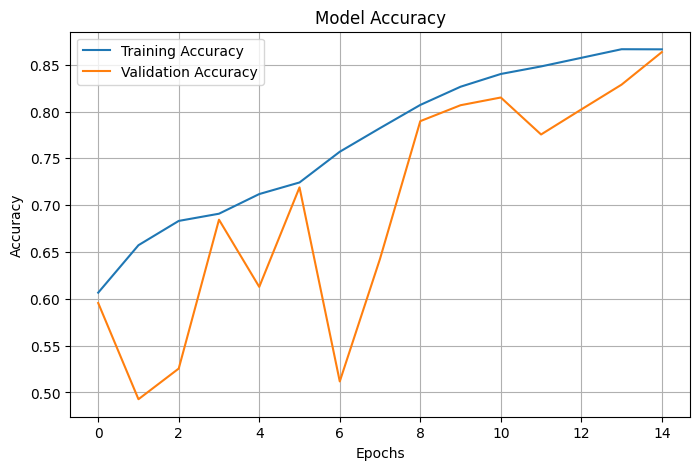

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)

plt.show()

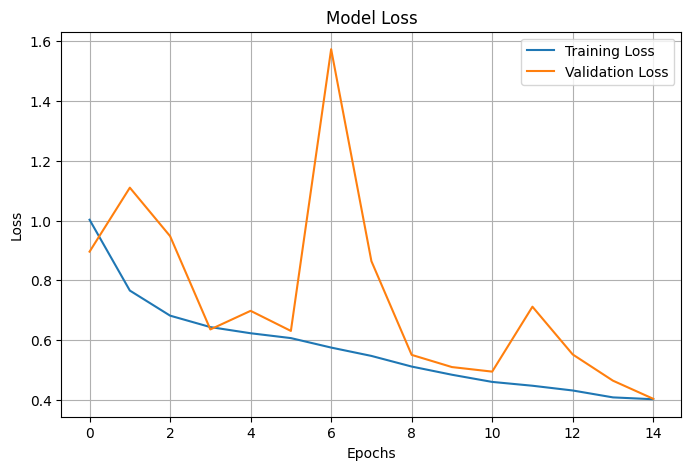

In [38]:
# loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

In [39]:
import cv2

In [40]:
test_img = cv2.imread('/content/dogs.jpg')

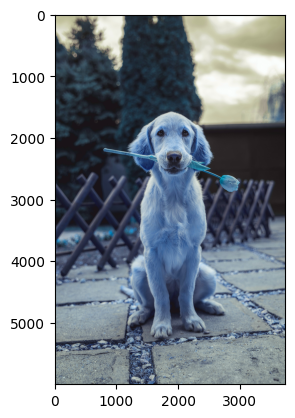

In [41]:
plt.imshow(test_img)

In [42]:
test_img.shape

(6000, 3742, 3)

In [44]:
test_img = cv2.resize(test_img,(256,256))

In [46]:
test_input = test_img.reshape((1,256,256,3))

In [47]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step


array([[1.]], dtype=float32)

In [56]:
test_img = cv2.imread('/content/cats.jpg')

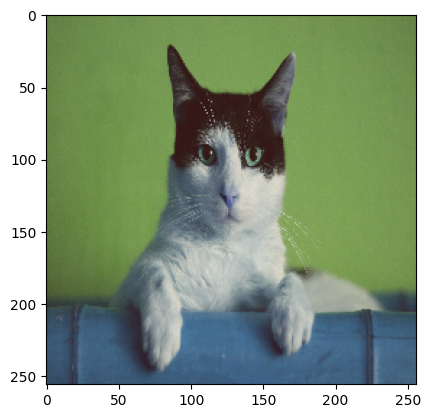

In [52]:
plt.imshow(test_img)

In [57]:
test_img.shape

(3458, 5026, 3)

In [58]:
test_img = cv2.resize(test_img,(256,256))

In [59]:
test_input = test_img.reshape((1,256,256,3))

In [60]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


array([[1.1622654e-16]], dtype=float32)